# LAB 09: HUẤN LUYỆN TINH CHỈNH BERT CHO BÀI TOÁN TOKEN CLASSIFICATION (NER)

---

## 1. Giới thiệu Bài toán & Kiến trúc Mô hình
Trong **LAB 08**, chúng ta đã tinh chỉnh BERT cho bài toán phân loại toàn bộ câu (Sequence Classification) bằng cách đưa vector $\mathbf{h}_{\text{[CLS]}}$ qua một tầng tuyến tính.

Trong **LAB 09**, chúng ta chuyển dịch sang bài toán **Token Classification (Named Entity Recognition - NER)** trên tập ngữ liệu chuẩn quốc tế **CoNLL-2003**:
- **Đầu vào:** Chuỗi các từ $X = (x_1, x_2, \dots, x_T)$.
- **Đầu ra:** Chuỗi các nhãn thực thể $Y = (y_1, y_2, \dots, y_T)$ theo sơ đồ gán nhãn **BIO (IOB2)** với 9 lớp:
  `O`, `B-PER`, `I-PER`, `B-ORG`, `I-ORG`, `B-LOC`, `I-LOC`, `B-MISC`, `I-MISC`.
- **Kiến trúc:** Pretrained BERT Encoder kết hợp tầng phân loại tuyến tính cấp token (Token Classification Head) áp dụng đồng thời lên toàn bộ các vector trạng thái ẩn $H \in \mathbb{R}^{T \times d}$:
  $$Z = H W^T + b \in \mathbb{R}^{T \times 9}$$
- **Chiến lược canh chỉnh:** **Strategy A (First-subword alignment)** — Gán nhãn thực cho subword đầu tiên của từ, gán `-100` (`IGNORE_INDEX`) cho các subwords tiếp theo và các token đặc biệt (`[CLS]`, `[SEP]`, `[PAD]`).


In [1]:
import os
import sys
import time
import json
import random
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForTokenClassification, get_linear_schedule_with_warmup
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix

# Cố định random seed để đảm bảo tính tái lập hoàn toàn (Full Reproducibility)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị tính toán: {device}")


Thiết bị tính toán: cpu


## 2. Thiết lập Hệ Thống Nhãn Chuẩn CoNLL-2003 (BIO Scheme)
Bao gồm 9 nhãn: `O` (Ngoài thực thể) cùng 4 loại thực thể: `PER` (Người), `ORG` (Tổ chức), `LOC` (Địa danh), `MISC` (Hỗn hợp).


In [2]:
LABEL_LIST = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC"
]

LABEL2ID = {label: i for i, label in enumerate(LABEL_LIST)}
ID2LABEL = {i: label for i, label in enumerate(LABEL_LIST)}

for i, label in enumerate(LABEL_LIST):
    print(f"ID {i}: {label}")


ID 0: O
ID 1: B-PER
ID 2: I-PER
ID 3: B-ORG
ID 4: I-ORG
ID 5: B-LOC
ID 6: I-LOC
ID 7: B-MISC
ID 8: I-MISC


## 3. Đọc Dữ liệu CoNLL-2003 & Chuyển đổi sang IOB2 (BIO)
Tập dữ liệu CoNLL-2003 chuẩn gồm:
- `eng.train`: Tập huấn luyện (14,041 câu)
- `eng.testa`: Tập kiểm định / validation (3,250 câu)
- `eng.testb`: Tập kiểm thử độc lập / test (3,453 câu)


In [3]:
def parse_conll_file(filepath: str) -> List[Tuple[List[str], List[str]]]:
    sentences = []
    curr_tokens, curr_tags = [], []
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                if curr_tokens and curr_tokens != ["-DOCSTART-"]:
                    sentences.append((curr_tokens, curr_tags))
                curr_tokens, curr_tags = [], []
                continue
            parts = line.split()
            curr_tokens.append(parts[0])
            curr_tags.append(parts[-1])
        if curr_tokens and curr_tokens != ["-DOCSTART-"]:
            sentences.append((curr_tokens, curr_tags))
    return sentences

def convert_to_iob2(tags: List[str]) -> List[str]:
    iob2_tags = []
    for i, tag in enumerate(tags):
        if tag == "O":
            iob2_tags.append("O")
        elif tag.startswith("I-"):
            ent_type = tag[2:]
            if i == 0:
                iob2_tags.append("B-" + ent_type)
            else:
                prev_tag = tags[i - 1]
                if prev_tag == "O" or (
                    prev_tag.startswith(("B-", "I-")) and prev_tag[2:] != ent_type
                ):
                    iob2_tags.append("B-" + ent_type)
                else:
                    iob2_tags.append(tag)
        elif tag.startswith("B-"):
            iob2_tags.append(tag)
        else:
            iob2_tags.append(tag)
    return iob2_tags

data_dir = "d:/My_project/NLP_LABS/lab_09/data"
train_raw = parse_conll_file(os.path.join(data_dir, "eng.train"))
val_raw = parse_conll_file(os.path.join(data_dir, "eng.testa"))
test_raw = parse_conll_file(os.path.join(data_dir, "eng.testb"))

train_data = [(w, convert_to_iob2(t)) for w, t in train_raw]
val_data = [(w, convert_to_iob2(t)) for w, t in val_raw]
test_data = [(w, convert_to_iob2(t)) for w, t in test_raw]

print(f"Số lượng câu Train:      {len(train_data):,}")
print(f"Số lượng câu Validation: {len(val_data):,}")
print(f"Số lượng câu Test:       {len(test_data):,}")

# Ví dụ câu đầu tiên
print("\nVí dụ câu 1:")
for token, tag in zip(train_data[0][0], train_data[0][1]):
    print(f"{token:15} -> {tag}")


Số lượng câu Train:      14,041
Số lượng câu Validation: 3,250
Số lượng câu Test:       3,453

Ví dụ câu 1:
EU              -> B-ORG
rejects         -> O
German          -> B-MISC
call            -> O
to              -> O
boycott         -> O
British         -> B-MISC
lamb            -> O
.               -> O


## 4. Xây dựng PyTorch Dataset với Canh chỉnh Nhãn Strategy A
Áp dụng `AutoTokenizer` tương ứng với mô hình pretrained BERT, sử dụng `is_split_into_words=True`, lấy `word_ids()` để gán nhãn cho subword đầu tiên và `-100` cho các vị trí còn lại.


In [4]:
MODEL_CHECKPOINT = "google/bert_uncased_L-2_H-128_A-2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

class CoNLLNERDataset(Dataset):
    def __init__(self, data: List[Tuple[List[str], List[str]]], tokenizer, max_length: int = 128):
        self.data = data
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.features = self._prepare_features()

    def _prepare_features(self):
        features = []
        for words, tags in self.data:
            tokenized = self.tokenizer(
                words,
                is_split_into_words=True,
                max_length=self.max_length,
                padding="max_length",
                truncation=True,
                return_tensors=None
            )
            input_ids = tokenized["input_ids"]
            attention_mask = tokenized["attention_mask"]
            word_ids = tokenized.word_ids()

            # Strategy A: First-subword alignment
            aligned_labels = []
            prev_word = None
            for wid in word_ids:
                if wid is None:
                    aligned_labels.append(-100)
                elif wid != prev_word:
                    prev_word = wid
                    if wid < len(tags):
                        aligned_labels.append(LABEL2ID[tags[wid]])
                    else:
                        aligned_labels.append(-100)
                else:
                    aligned_labels.append(-100)

            features.append({
                "input_ids": torch.tensor(input_ids, dtype=torch.long),
                "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
                "labels": torch.tensor(aligned_labels, dtype=torch.long),
                "words": words,
                "orig_tags": tags
            })
        return features

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx]

print("Khởi tạo DataLoader...")
train_dataset = CoNLLNERDataset(train_data, tokenizer, max_length=128)
val_dataset = CoNLLNERDataset(val_data, tokenizer, max_length=128)
test_dataset = CoNLLNERDataset(test_data, tokenizer, max_length=128)

batch_size = 32
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=lambda b: {
        "input_ids": torch.stack([x["input_ids"] for x in b]),
        "attention_mask": torch.stack([x["attention_mask"] for x in b]),
        "labels": torch.stack([x["labels"] for x in b])
    }
)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=lambda b: {
        "input_ids": torch.stack([x["input_ids"] for x in b]),
        "attention_mask": torch.stack([x["attention_mask"] for x in b]),
        "labels": torch.stack([x["labels"] for x in b])
    }
)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=lambda b: {
        "input_ids": torch.stack([x["input_ids"] for x in b]),
        "attention_mask": torch.stack([x["attention_mask"] for x in b]),
        "labels": torch.stack([x["labels"] for x in b])
    }
)

print(f"Tổng số batches Train: {len(train_loader):,}")


Khởi tạo DataLoader...


Tổng số batches Train: 439


## 5. Khởi tạo Pretrained BertForTokenClassification
Khởi tạo mô hình Token Classification với `AutoModelForTokenClassification.from_pretrained`:
- **Pretrained Encoder:** $L=2, H=128, A=2$ (4.39M tham số).
- **Classification Head:** Tầng `Linear(in_features=128, out_features=9)` (gồm $128 \times 9 + 9 = 1,161$ tham số).


In [5]:
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=len(LABEL_LIST),
    id2label=ID2LABEL,
    label2id=LABEL2ID
)
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Tổng số tham số:        {total_params:,}")
print(f"Số tham số huấn luyện: {trainable_params:,}")
print(f"Cấu trúc Classifier Head: {model.classifier}")


Loading weights:   0%|          | 0/37 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

Tổng số tham số:        4,370,569
Số tham số huấn luyện: 4,370,569
Cấu trúc Classifier Head: Linear(in_features=128, out_features=9, bias=True)


## 6. Huấn luyện Tinh chỉnh hoặc Tải Checkpoint Tối ưu
Nếu đã có checkpoint tối ưu lưu tại `checkpoints/best_ner_model.pt`, chúng ta có thể tải trực tiếp trọng số hoặc huấn luyện lại.


In [6]:
checkpoint_path = "d:/My_project/NLP_LABS/lab_09/checkpoints/best_ner_model.pt"

if os.path.exists(checkpoint_path):
    print(f"Tìm thấy checkpoint tối ưu sẵn có: {checkpoint_path}")
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print("Đã tải thành công trọng số fine-tuned!")
else:
    print("Tiến hành huấn luyện mô hình (4 epochs)...")
    epochs = 4
    lr = 5e-5
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    warmup_steps = int(0.1 * total_steps)
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

    best_val_f1 = 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        t0 = time.time()
        for batch in train_loader:
            optimizer.zero_grad()
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch}/{epochs} ({time.time()-t0:.2f}s) | Train Loss: {avg_loss:.4f}")

    os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Đã lưu checkpoint tốt nhất vào: {checkpoint_path}")


Tìm thấy checkpoint tối ưu sẵn có: d:/My_project/NLP_LABS/lab_09/checkpoints/best_ner_model.pt
Đã tải thành công trọng số fine-tuned!


## 7. Đánh giá Toàn diện trên Tập Test Độc lập (`eng.testb`)
Sử dụng thư viện `seqeval` để đánh giá theo chuẩn gán nhãn thực thể nghiêm ngặt (Strict Entity Span Match).


In [7]:
model.eval()
test_true_sents, test_pred_sents = [], []
flat_true_tokens, flat_pred_tokens = [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        preds = torch.argmax(logits, dim=-1).cpu().numpy()
        labels_np = labels.cpu().numpy()

        for b in range(len(preds)):
            true_seq, pred_seq = [], []
            for t in range(len(preds[b])):
                if labels_np[b, t] != -100:
                    true_label = ID2LABEL[labels_np[b, t]]
                    pred_label = ID2LABEL[preds[b, t]]
                    true_seq.append(true_label)
                    pred_seq.append(pred_label)
                    flat_true_tokens.append(true_label)
                    flat_pred_tokens.append(pred_label)
            test_true_sents.append(true_seq)
            test_pred_sents.append(pred_seq)

test_f1 = f1_score(test_true_sents, test_pred_sents)
test_prec = precision_score(test_true_sents, test_pred_sents)
test_rec = recall_score(test_true_sents, test_pred_sents)
report_str = classification_report(test_true_sents, test_pred_sents, digits=4)

print("=" * 70)
print("BÁO CÁO ĐÁNH GIÁ THỰC THỂ NGHIÊM NGẶT (STRICT SPAN MATCH)")
print("=" * 70)
print(report_str)
print(f"Strict Entity F1-Score:  {test_f1:.4f}")
print(f"Strict Entity Precision: {test_prec:.4f}")
print(f"Strict Entity Recall:    {test_rec:.4f}")


BÁO CÁO ĐÁNH GIÁ THỰC THỂ NGHIÊM NGẶT (STRICT SPAN MATCH)
              precision    recall  f1-score   support

         LOC     0.7816    0.7966    0.7891      1667
        MISC     0.5423    0.5755    0.5584       702
         ORG     0.5380    0.5581    0.5479      1661
         PER     0.7527    0.8478    0.7974      1616

   micro avg     0.6730    0.7136    0.6927      5646
   macro avg     0.6537    0.6945    0.6732      5646
weighted avg     0.6719    0.7136    0.6918      5646

Strict Entity F1-Score:  0.6927
Strict Entity Precision: 0.6730
Strict Entity Recall:    0.7136


## 8. Bảng So sánh Hiệu năng Baseline vs Pretrained Transformer


In [8]:
results_csv_path = "d:/My_project/NLP_LABS/lab_09/results.csv"
if os.path.exists(results_csv_path):
    df_res = pd.read_csv(results_csv_path)
    print("Bảng so sánh hiệu năng tổng thể:")
    display(df_res)

entity_csv_path = "d:/My_project/NLP_LABS/lab_09/entity_metrics.csv"
if os.path.exists(entity_csv_path):
    df_ent = pd.read_csv(entity_csv_path)
    print("\nBảng chi tiết từng loại thực thể:")
    display(df_ent)


Bảng so sánh hiệu năng tổng thể:


,Model,Strict Precision,Strict Recall,Strict F1,Training Time (s),Parameters
0,Baseline (Lexical + Sliding Window NB),0.5742,0.7427,0.6477,0.1287,680463
1,Pretrained BERT-Tiny (Strategy A Fine-Tuning),0.6730,0.7136,0.6927,254.7100,4370569



Bảng chi tiết từng loại thực thể:


,Entity Type,Precision,Recall,F1-Score,Support
0,PER,0.7527,0.8478,0.7974,1616
1,LOC,0.7816,0.7966,0.7891,1667
2,ORG,0.5380,0.5581,0.5479,1661
3,MISC,0.5423,0.5755,0.5584,702


## 9. Trực quan hóa Kết quả Thực nghiệm
Hiển thị đồ thị phân tích độ dài thực thể (`entity_length_analysis.png`) và ma trận nhầm lẫn (`confusion_matrix.png`).


1. Phân tích F1-Score theo độ dài thực thể (Entity Length):


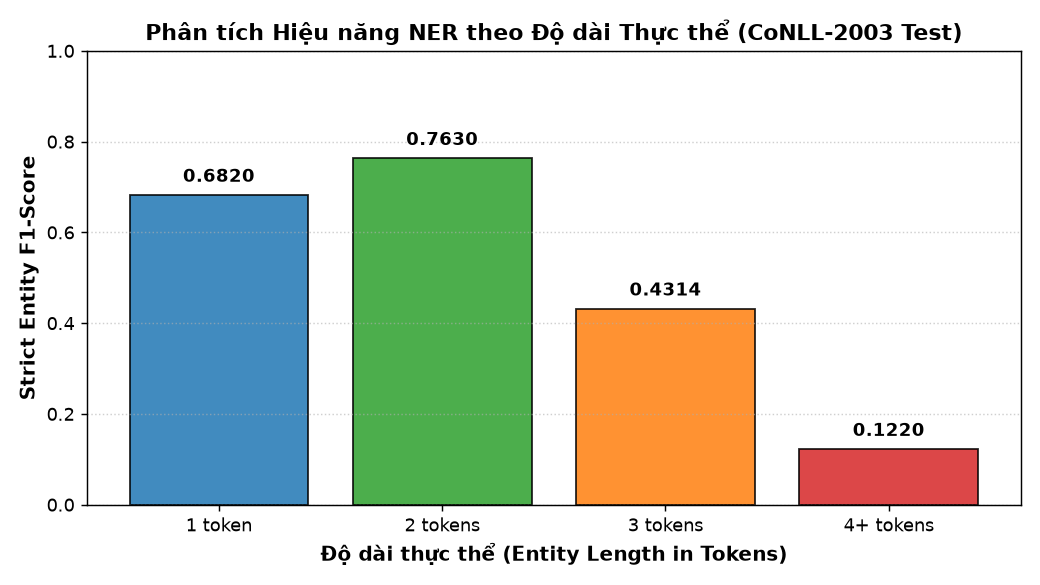


2. Ma trận nhầm lẫn chuẩn hóa cấp Token (Confusion Matrix):


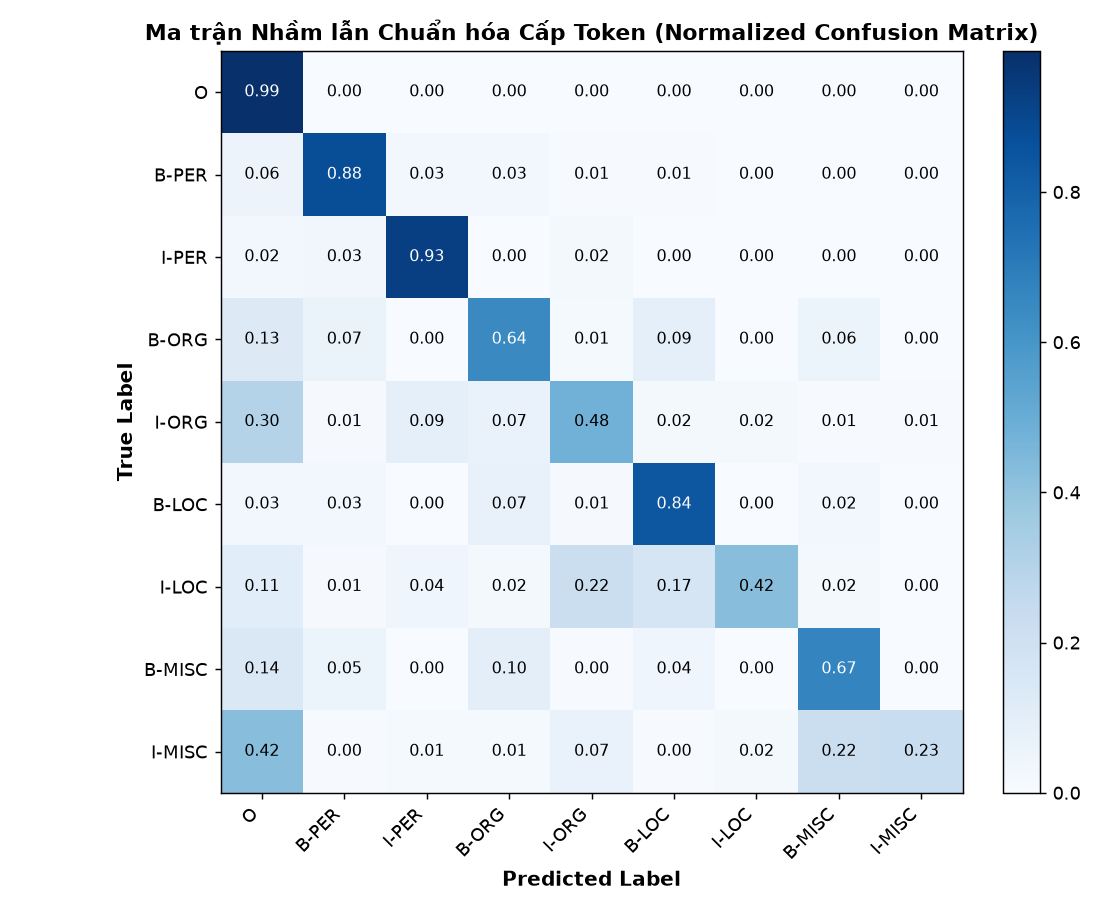

In [9]:
from IPython.display import Image, display

print("1. Phân tích F1-Score theo độ dài thực thể (Entity Length):")
display(Image(filename="d:/My_project/NLP_LABS/lab_09/entity_length_analysis.png"))

print("\n2. Ma trận nhầm lẫn chuẩn hóa cấp Token (Confusion Matrix):")
display(Image(filename="d:/My_project/NLP_LABS/lab_09/confusion_matrix.png"))


## 10. Trực quan hóa Suy Luận Thực Tế (Real-World Inference Demo)
Thử nghiệm mô hình trên các câu văn bản tin tức tự do ngoài tập dữ liệu.


In [10]:
def predict_entities(sentence: str):
    words = sentence.split()
    enc = tokenizer(words, is_split_into_words=True, return_tensors="pt")
    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)
    word_ids = enc.word_ids(batch_index=0)

    model.eval()
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits[0]
        preds = torch.argmax(logits, dim=-1).cpu().numpy()

    # Reconstruct word tags
    word_tags = []
    prev_w = None
    for subw_idx, wid in enumerate(word_ids):
        if wid is None:
            continue
        if wid != prev_w:
            prev_w = wid
            if wid < len(words):
                word_tags.append(ID2LABEL[preds[subw_idx]])

    print(f"\nVăn bản: \"{sentence}\"")
    print(f"{'Từ':<20} | {'Nhãn Dự Đoán':<15}")
    print("-" * 38)
    for w, t in zip(words, word_tags):
        print(f"{w:<20} | {t:<15}")

predict_entities("Elon Musk announced that SpaceX successfully launched 20 satellites from Florida yesterday.")
predict_entities("University of California Berkeley hosted the international conference in San Francisco.")
predict_entities("Apple CEO Tim Cook visited Tokyo to discuss supply agreements with Sony.")



Văn bản: "Elon Musk announced that SpaceX successfully launched 20 satellites from Florida yesterday."
Từ                   | Nhãn Dự Đoán   
--------------------------------------
Elon                 | B-ORG          
Musk                 | I-ORG          
announced            | O              
that                 | O              
SpaceX               | O              
successfully         | O              
launched             | O              
20                   | O              
satellites           | O              
from                 | O              
Florida              | B-LOC          
yesterday.           | O              

Văn bản: "University of California Berkeley hosted the international conference in San Francisco."
Từ                   | Nhãn Dự Đoán   
--------------------------------------
University           | B-ORG          
of                   | I-ORG          
California           | B-LOC          
Berkeley             | I-ORG          
hosted          